# AIDA 1141 Project Exercise 07 – Evaluation Measures

**Question:** How do the Exercise 06 model and the Exercise 05 rules compare when evaluated with confusion matrices and standard classification measures, and which errors matter most to the fictional coordinator?

This notebook uses the saved Exercise 06 validation predictions; nothing is refitted and test data is not used. Results are evaluated on the 505 validation early-warning assessments, and at task level for the coordinator's view.

All results describe methods applied to simulated outcomes; they are not evidence about real employees or HR performance.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score

EX02 = Path("../02-synthetic-request-records")
EX06 = Path("../06-model-training-and-split")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

METHODS = {"logistic_regression": "Logistic regression",
           "days_until_start_rule": "Days rule (global)",
           "days_rule_by_employee_type": "Days rule (by employee type)"}

predictions = pd.read_csv(EX06 / "outputs" / "validation_predictions.csv")
assessments = pd.read_csv(EX02 / "data" / "assessments.csv", usecols=["assessment_id", "business_days_until_start"])
requests = pd.read_csv(EX02 / "data" / "requests.csv", usecols=["request_id", "task_type"])
validation = (predictions.merge(assessments, on="assessment_id", how="left", validate="one_to_one")
              .merge(requests, on="request_id", how="left", validate="many_to_one"))
ex06_comparison = pd.read_csv(EX06 / "outputs" / "model_vs_baselines.csv", index_col=0)
print(f"Loaded {len(validation)} validation assessments")

Loaded 526 validation assessments


## A. Consistency with Exercise 06

The predictions come from Exercise 06, with each assessment's days until start (used as the rule's ranking score in Part C) and task type added from the Exercise 02 files. These checks confirm the inputs are complete and that the confusion counts reproduce Exercise 06 exactly.

In [2]:
BOOLEAN_COLUMNS = ["early_warning", "at_risk"] + list(METHODS)
boolean_ok = all(validation[c].dtype == bool for c in BOOLEAN_COLUMNS)   # True/False only, no blanks
assert boolean_ok, "A flag or label column contains missing or non-Boolean values."
early = validation[validation["early_warning"]]

def confusion_counts(actual, flagged):
    """True/false positives and negatives for one set of yes/no flags."""
    return {"TP": int((flagged & actual).sum()), "FP": int((flagged & ~actual).sum()),
            "FN": int((~flagged & actual).sum()), "TN": int((~flagged & ~actual).sum())}

assessment_confusion = pd.DataFrame({m: confusion_counts(early["at_risk"], early[m]) for m in METHODS}).T
consistency_checks = pd.Series({
    "526 validation assessments, one row each": len(validation) == 526 and validation["assessment_id"].is_unique,
    "505 early-warning assessments, 84 at risk": len(early) == 505 and early["at_risk"].sum() == 84,
    "Label, early-warning, and flag columns are True/False only": boolean_ok,
    "Every assessment matched its days-until-start value": validation["business_days_until_start"].notna().all(),
    "Every request matched its task type": validation["task_type"].notna().all(),
    "Every probability is between 0 and 1": validation["risk_probability"].between(0, 1).all(),
    "Confusion counts match Exercise 06":
        (assessment_confusion == ex06_comparison.loc[list(METHODS), ["TP", "FP", "FN", "TN"]]).all().all(),
}, name="passed")
assert consistency_checks.all(), "Validation predictions do not match Exercise 06."
consistency_checks.to_frame()

,passed
"526 validation assessments, one row each",True
"505 early-warning assessments, 84 at risk",True
"Label, early-warning, and flag columns are True/False only",True
Every assessment matched its days-until-start value,True
Every request matched its task type,True
Every probability is between 0 and 1,True
Confusion counts match Exercise 06,True


## B. Confusion matrices (assessment level)

The positive class is `at_risk = True`: the task finishes after 08:00 on its confirmed start date in the no-intervention simulation. A flag is a method's prediction that an assessment belongs to the positive class.

Each validation early-warning assessment falls into one of four cells:

- **True positive:** at risk and flagged.
- **False negative:** at risk but not flagged — a missed warning.
- **False positive:** not at risk but flagged — a follow-up that may not have been needed.
- **True negative:** not at risk and not flagged.

The chart compares the model with the global days rule; all three methods are listed in the table. Both panels use the same colour scale, so shading can be compared between them.

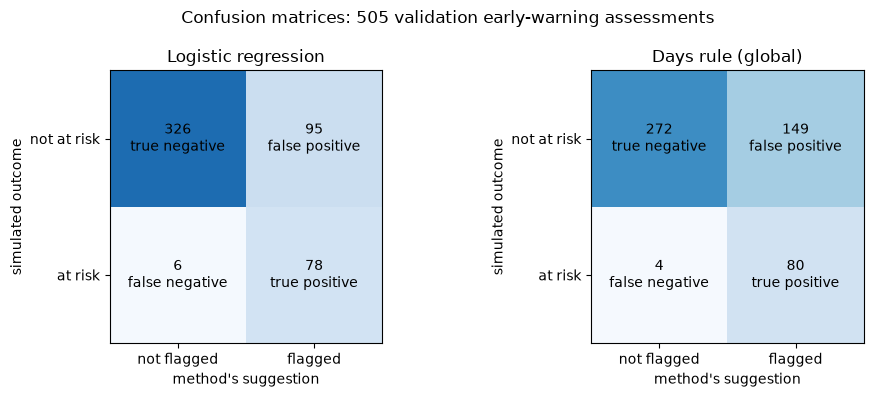

,TP,FP,FN,TN
logistic_regression,78,95,6,326
days_until_start_rule,80,149,4,272
days_rule_by_employee_type,79,150,5,271


In [3]:
assessment_confusion.to_csv(OUTPUT_DIR / "confusion_matrices_assessments.csv")

shown = ["logistic_regression", "days_until_start_rule"]
colour_max = assessment_confusion.loc[shown].to_numpy().max() * 1.3   # one scale for both panels
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, method in zip(axes, shown):
    c = assessment_confusion.loc[method]
    grid = np.array([[c["TN"], c["FP"]], [c["FN"], c["TP"]]])
    ax.imshow(grid, cmap="Blues", vmin=0, vmax=colour_max)
    for (i, j), value in np.ndenumerate(grid):
        label = [["true negative", "false positive"], ["false negative", "true positive"]][i][j]
        ax.text(j, i, f"{value}\n{label}", ha="center", va="center", fontsize=10)
    ax.set_xticks([0, 1], ["not flagged", "flagged"])
    ax.set_yticks([0, 1], ["not at risk", "at risk"])
    ax.set_xlabel("method's suggestion")
    ax.set_ylabel("simulated outcome")
    ax.set_title(METHODS[method])
fig.suptitle("Confusion matrices: 505 validation early-warning assessments")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=120)
plt.show()

assessment_confusion

## C. Classification measures

**At each method's chosen threshold** (from its confusion counts):

- **Accuracy:** share of all assessments classified correctly. Secondary here: because most assessments are not at risk, a method that flags nothing still scores highly.
- **Precision:** of the flagged assessments, the share that were at risk.
- **Recall:** of the at-risk assessments, the share that were flagged. This is the main measure because of the 90% target.
- **Specificity:** of the assessments not at risk, the share that were not flagged.
- **F1:** the harmonic mean of precision and recall, calculated directly from the counts as 2·TP ÷ (2·TP + FP + FN).

**Threshold-independent ranking measures** use each method's score rather than its yes/no flags: the model's estimated risk probability, and the negative of business days until start for the days rule (fewer days means higher risk). They describe how well each method orders assessments by risk across all possible thresholds, not its performance at the chosen threshold.

- **ROC AUC:** how often an at-risk assessment receives a higher score than a non-at-risk assessment, with tied scores receiving half credit (0.5 = random ordering). Ties matter here because many assessments share the same number of days until start.
- **Average precision:** summarizes precision across recall levels; a random ordering would score approximately the at-risk share, which is printed for reference.

Ranking measures are reported for the model and global days score only. The employee-type rule is evaluated through its saved binary flags. These measures describe discrimination (how well cases are ordered), not whether the estimated probabilities are well calibrated or whether a method would provide operational benefit. The validation set is small and clustered by task and employee, so small differences should not be treated as meaningful.

Despite its name, logistic regression is used here for binary classification. Regression measures for predicting a continuous duration are therefore not used. Predicting task lateness would be an alternative design, but it is outside this experiment.

In [4]:
def threshold_measures(counts):
    """Measures at a method's chosen threshold, from its confusion counts."""
    tp, fp, fn, tn = counts["TP"], counts["FP"], counts["FN"], counts["TN"]
    f1_denominator = 2 * tp + fp + fn
    return pd.Series({
        "accuracy": (tp + tn) / (tp + fp + fn + tn),
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
        "specificity": tn / (tn + fp) if tn + fp else np.nan,
        "f1": 2 * tp / f1_denominator if f1_denominator else np.nan,
    })

assessment_metrics = assessment_confusion.apply(threshold_measures, axis=1)
assessment_metrics.round(3).to_csv(OUTPUT_DIR / "metrics_assessments.csv")

# Threshold-independent ranking measures use each method's score, not its yes/no flags
ranking_scores = {"logistic_regression": early["risk_probability"],
                  "days_until_start_rule": -early["business_days_until_start"]}   # fewer days = higher risk
ranking_measures = pd.DataFrame({
    method: {"roc_auc": roc_auc_score(early["at_risk"], score),
             "average_precision": average_precision_score(early["at_risk"], score)}
    for method, score in ranking_scores.items()}).T
ranking_measures.round(3).to_csv(OUTPUT_DIR / "ranking_measures.csv")

print(f"At-risk share of validation early-warning assessments (approximate average-precision reference): "
      f"{early['at_risk'].mean():.3f}")
display(assessment_metrics.round(3))
ranking_measures.round(3)

At-risk share of validation early-warning assessments (approximate average-precision reference): 0.166


,accuracy,precision,recall,specificity,f1
logistic_regression,0.800,0.451,0.929,0.774,0.607
days_until_start_rule,0.697,0.349,0.952,0.646,0.511
days_rule_by_employee_type,0.693,0.345,0.940,0.644,0.505


,roc_auc,average_precision
logistic_regression,0.941,0.807
days_until_start_rule,0.882,0.629


## D. Task-level view

The coordinator acts on tasks, while each task can be assessed at up to two checkpoints. This section aggregates the flags to one row per task.

**Task population:** validation tasks with at least one early-warning assessment. Tasks assessed only after the deadline are excluded and their count is reported. A task's label is checked to be the same across all its validation assessments, and a task counts as **flagged** if any of its early-warning assessments was flagged. Flagged means flagged at least once before the deadline, not necessarily early enough for effective intervention.

Task-level counts are calculated from the aggregated task flags, not by relabelling the assessment counts, because two flags on the same task are one task for the coordinator.

**Lead time** uses the weekday count until start (`business_days_until_start`), which includes the assessment date and is not a count of full working days remaining. For the at-risk tasks each method flagged, the count at its earliest flag is summarized. The methods flagged different sets of tasks, so a paired comparison also looks at the at-risk tasks both methods flagged and whether the model's first flag came on an earlier, the same, or a later weekday count than the rule's. Counts are date-based, so flags made at different times on the same day cannot be distinguished.

The final table lists the at-risk tasks each method never flagged, with their assessments, for review in Exercise 08.

In [5]:
# Task population: validation tasks with at least one early-warning assessment
assert validation.groupby("request_id")["at_risk"].nunique().eq(1).all(), "A task has inconsistent labels."
tasks = early.groupby("request_id").agg(at_risk=("at_risk", "first"), task_type=("task_type", "first"),
                                        early_warning_assessments=("assessment_id", "size"),
                                        **{m: (m, "any") for m in METHODS})
overdue_only_tasks = set(validation["request_id"]) - set(early["request_id"])

task_confusion = pd.DataFrame({m: confusion_counts(tasks["at_risk"], tasks[m]) for m in METHODS}).T
task_metrics = task_confusion.apply(threshold_measures, axis=1)
task_confusion.join(task_metrics.round(3)).to_csv(OUTPUT_DIR / "confusion_and_metrics_tasks.csv")

# Lead time: weekday count until start at each method's earliest flag on the at-risk tasks it flagged
first_flag = {m: early[early["at_risk"] & early[m]].groupby("request_id")["business_days_until_start"].max()
              for m in METHODS}
lead_time = pd.DataFrame({m: {"at_risk_tasks_flagged": len(first_flag[m]),
                              "median_weekdays_until_start_at_first_flag": first_flag[m].median(),
                              "fewest_weekdays_until_start_at_first_flag": first_flag[m].min()}
                          for m in METHODS}).T
lead_time.to_csv(OUTPUT_DIR / "task_lead_time.csv")

# Paired comparison on the at-risk tasks both the model and the global rule flagged
paired = first_flag["logistic_regression"].to_frame("model").join(
    first_flag["days_until_start_rule"].rename("global_rule"), how="inner")
gap = paired["model"] - paired["global_rule"]
paired_timing = pd.Series({"at-risk tasks flagged by both": len(paired),
                           "model flagged on an earlier weekday count": int((gap > 0).sum()),
                           "same weekday count": int((gap == 0).sum()),
                           "model flagged on a later weekday count": int((gap < 0).sum())}, name="tasks")

# At-risk tasks each method never flagged, with their early-warning assessments
missed = pd.concat([tasks[tasks["at_risk"] & ~tasks[m]].assign(method=m) for m in METHODS])
missed_assessments = (missed[["method"]].reset_index()
                      .merge(early[["request_id", "assessment_id", "checkpoint", "task_type",
                                    "business_days_until_start", "risk_probability"]], on="request_id"))
missed_assessments.to_csv(OUTPUT_DIR / "missed_at_risk_tasks.csv", index=False)

print(f"{len(tasks)} tasks with early-warning assessments ({int(tasks['at_risk'].sum())} at risk); "
      f"{len(overdue_only_tasks)} tasks assessed only after the deadline are excluded")
display(task_confusion.join(task_metrics.round(3)))
display(lead_time)
display(paired_timing.to_frame())
missed_assessments.round(3)

397 tasks with early-warning assessments (64 at risk); 21 tasks assessed only after the deadline are excluded


,TP,FP,FN,TN,accuracy,precision,recall,specificity,f1
logistic_regression,62,67,2,266,0.826,0.481,0.969,0.799,0.642
days_until_start_rule,64,107,0,226,0.730,0.374,1.000,0.679,0.545
days_rule_by_employee_type,64,111,0,222,0.720,0.366,1.000,0.667,0.536


,at_risk_tasks_flagged,median_weekdays_until_start_at_first_flag,fewest_weekdays_until_start_at_first_flag
logistic_regression,62.0,4.0,1.0
days_until_start_rule,64.0,4.0,1.0
days_rule_by_employee_type,64.0,4.0,1.0


,tasks
at-risk tasks flagged by both,62
model flagged on an earlier weekday count,2
same weekday count,58
model flagged on a later weekday count,2


,request_id,method,assessment_id,checkpoint,task_type,business_days_until_start,risk_probability
0,REQ-00263,logistic_regression,ASM-00285,checkpoint_1,workplace_access,11,0.011
1,REQ-00263,logistic_regression,ASM-00355,checkpoint_2,workplace_access,5,0.044
2,REQ-02052,logistic_regression,ASM-02557,checkpoint_1,payroll_setup,8,0.097
3,REQ-02052,logistic_regression,ASM-02569,checkpoint_2,payroll_setup,5,0.090


## E. Cost-sensitivity analysis

Real costs of each error are not known, so instead of assigning them, this section finds where the comparison between the model and the global days rule changes. Let one false positive (an unnecessary flag) count as one unit, and one false negative (a missed at-risk case) count as *r* units. Each method's calculated cost is then FP + *r* × FN.

The **break-even ratio** is the value of *r* where the two methods have equal calculated cost: the model's reduction in false positives divided by its increase in false negatives. Below that ratio the model has lower calculated cost; above it, the rule does; at it, they tie. Assessment and task calculations are reported separately because several flags may concern one task. Neither level measures actual coordinator effort.

The chart's range of ratios (1 to 60) is illustrative; it does not suggest that these values are realistic or endorsed by the fictional team. This is a conditional calculation, not evidence of operational savings. It assumes every false positive costs the same and every false negative costs the same, ignores the cost of correct decisions, and does not account for missed tasks of different types having different consequences.

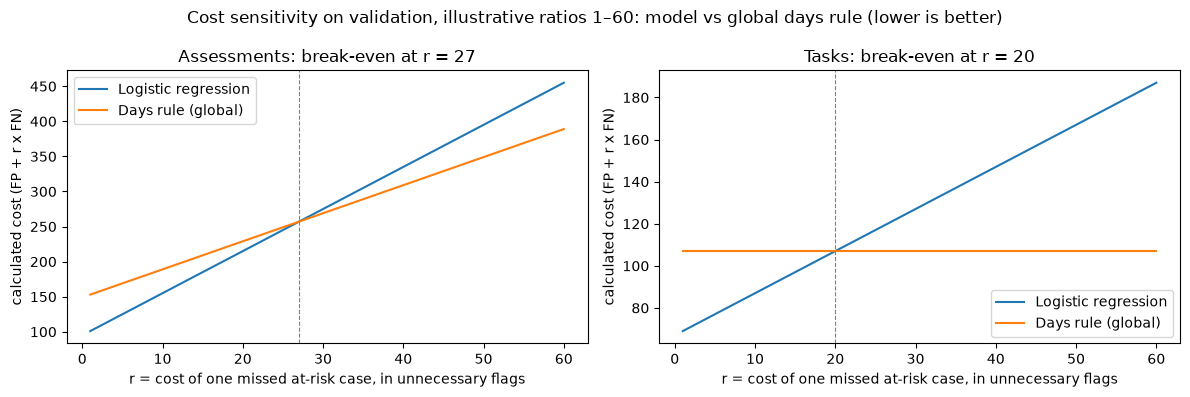

,fewer_false_positives,more_false_negatives,break_even_ratio
assessments,54.0,2.0,27.0
tasks,40.0,2.0,20.0


In [6]:
def break_even_ratio(confusion, method, comparison):
    """Ratio r at which FP + r x FN is equal, for a method with fewer false positives and more false negatives."""
    fewer_fp = confusion.at[comparison, "FP"] - confusion.at[method, "FP"]
    more_fn = confusion.at[method, "FN"] - confusion.at[comparison, "FN"]
    assert fewer_fp > 0 and more_fn > 0, "This calculation expects fewer false positives and more false negatives."
    return fewer_fp, more_fn, fewer_fp / more_fn

levels = {"assessments": assessment_confusion, "tasks": task_confusion}
break_even = pd.DataFrame(
    {level: dict(zip(["fewer_false_positives", "more_false_negatives", "break_even_ratio"],
                     break_even_ratio(confusion, "logistic_regression", "days_until_start_rule")))
     for level, confusion in levels.items()}).T
break_even.to_csv(OUTPUT_DIR / "break_even.csv")

# Calculated cost for each method across an illustrative range of ratios
ratios = np.arange(1, 61)
cost_rows = []
for level, confusion in levels.items():
    for method in ["logistic_regression", "days_until_start_rule"]:
        for r in ratios:
            cost_rows.append({"level": level, "method": method, "ratio": r,
                              "calculated_cost": confusion.at[method, "FP"] + r * confusion.at[method, "FN"]})
cost_sensitivity = pd.DataFrame(cost_rows)
cost_sensitivity.to_csv(OUTPUT_DIR / "cost_sensitivity.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, level in zip(axes, levels):
    for method in ["logistic_regression", "days_until_start_rule"]:
        line = cost_sensitivity.query("level == @level and method == @method")
        ax.plot(line["ratio"], line["calculated_cost"], label=METHODS[method])
    ax.axvline(break_even.at[level, "break_even_ratio"], color="grey", ls="--", lw=0.8)
    ax.set_title(f"{level.capitalize()}: break-even at r = {break_even.at[level, 'break_even_ratio']:g}")
    ax.set_xlabel("r = cost of one missed at-risk case, in unnecessary flags")
    ax.set_ylabel("calculated cost (FP + r x FN)")
    ax.legend()
fig.suptitle("Cost sensitivity on validation, illustrative ratios 1–60: model vs global days rule (lower is better)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cost_sensitivity.png", dpi=120)
plt.show()

break_even

## F. Which errors matter most

**False negatives matter most.** A false negative is an at-risk task that receives no early-warning flag. If the coordinator does not otherwise notice it, a new employee may start without the payroll setup, system or workplace access, equipment, or orientation the task covers. This is why the project uses a 90% recall target for early-warning assessments. The consequences may differ by task type: missing access or payroll setup may matter more than a late orientation booking, but the fictional team has not ranked them, so this analysis treats all misses alike.

**False positives create a different kind of cost.** A false positive is a flag on a task that would have been ready in time. It may create avoidable review work for the coordinator, but flag counts do not measure actual staff time. An unnecessary flag may be dismissed after review, but repeated checks can still consume coordinator time.

**What the measures show on this validation split.** Both the model and the global days rule met the 90% recall target at assessment level (92.9% and 95.2%). At task level, the global rule flagged all 64 at-risk tasks at least once, while the model flagged 62: two at-risk tasks, one payroll setup and one workplace access, received no early-warning flag from the model. In exchange, the model made 54 fewer false-positive assessment flags and 40 fewer false-positive task flags, with higher observed precision, specificity, F1, ROC AUC, and average precision. Among the 62 at-risk tasks both methods flagged, the first flag came on the same weekday count for 58.

**What would decide between them.** The preferred method depends on how the team values a missed at-risk case against unnecessary flags. At task level, the global rule has lower calculated cost when one missed at-risk task costs more than 20 unnecessary task flags. At assessment level, the corresponding ratio is 27. Below each ratio, the model has lower calculated cost; at the ratio, they tie. These results do not choose a preferred method until the team supplies its priorities or cost assumptions.

**Limits.** These results describe methods applied to simulated outcomes, not real employees or HR performance. The difference in missed tasks rests on two tasks in a small, clustered validation set, so it should not be treated as a reliable estimate. Employees are separated across splits, but the splits cover overlapping dates. Results therefore assess held-out employees within the simulated period, rather than performance on a later period or under changing conditions. Exercise 08 will review the missed and incorrectly flagged cases, and Exercise 09 will compare thresholds for both methods on validation before one final test evaluation.